# Exploratory Data Analysis

## Project Objective

This notebook explores food delivery performance and identifies the factors associated with longer delivery times.

## Business Question

> What factors are causing food deliveries to take longer, and where should the company take action to reduce delivery delays?

## Analysis Areas

1. Overall delivery performance
2. Delivery time distribution
3. Traffic impact
4. Weather impact
5. Weather × traffic interaction
6. Distance impact
7. Vehicle analysis
8. Delivery partner analysis
9. Multiple deliveries
10. City analysis
11. Outlier analysis
12. Correlation analysis

The analysis will focus on business-relevant patterns rather than producing charts without a specific question.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/cleaned/food_delivery_cleaned.csv")

In [3]:
df.shape

(45593, 20)

In [4]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37.0,4.9,22.745049,75.892471,22.765049,75.912471,2022-03-19,1900-01-01 11:30:00,1900-01-01 11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,24
1,0xb379,BANGRES18DEL02,34.0,4.5,12.913041,77.683237,13.043041,77.813237,2022-03-25,1900-01-01 19:45:00,1900-01-01 19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,33
2,0x5d6d,BANGRES19DEL01,23.0,4.4,12.914264,77.678400,12.924264,77.688400,2022-03-19,1900-01-01 08:30:00,1900-01-01 08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,26
3,0x7a6a,COIMBRES13DEL02,38.0,4.7,11.003669,76.976494,11.053669,77.026494,2022-04-05,1900-01-01 18:00:00,1900-01-01 18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,21
4,0x70a2,CHENRES12DEL01,32.0,4.6,12.972793,80.249982,13.012793,80.289982,2022-03-26,1900-01-01 13:30:00,1900-01-01 13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,30


## 1. Overall Delivery Performance

Before analyzing individual factors, we first establish the overall delivery-time performance of the business.

### Business Questions

- What is the average delivery time?
- What is the typical (median) delivery time?
- What are the fastest and slowest deliveries?
- What percentage of orders take more than 30 minutes?

In [5]:
avg_delivery_time = df["Time_taken(min)"].mean()
median_delivery_time = df["Time_taken(min)"].median()
min_delivery_time = df["Time_taken(min)"].min()
max_delivery_time = df["Time_taken(min)"].max()

late_delivery_pct = ((df["Time_taken(min)"] > 30).mean() * 100)

print("Average delivery time:", round(avg_delivery_time, 2), "minutes")
print("Median delivery time:", median_delivery_time, "minutes")
print("Minimum delivery time:", min_delivery_time, "minutes")
print("Maximum delivery time:", max_delivery_time, "minutes")
print("Deliveries above 30 minutes:", round(late_delivery_pct, 2), "%")

Average delivery time: 26.29 minutes
Median delivery time: 26.0 minutes
Minimum delivery time: 10 minutes
Maximum delivery time: 54 minutes
Deliveries above 30 minutes: 29.84 %


### Delivery Time Distribution

A distribution plot helps us understand how delivery times are spread across all orders and whether there are noticeable concentrations or unusual values.

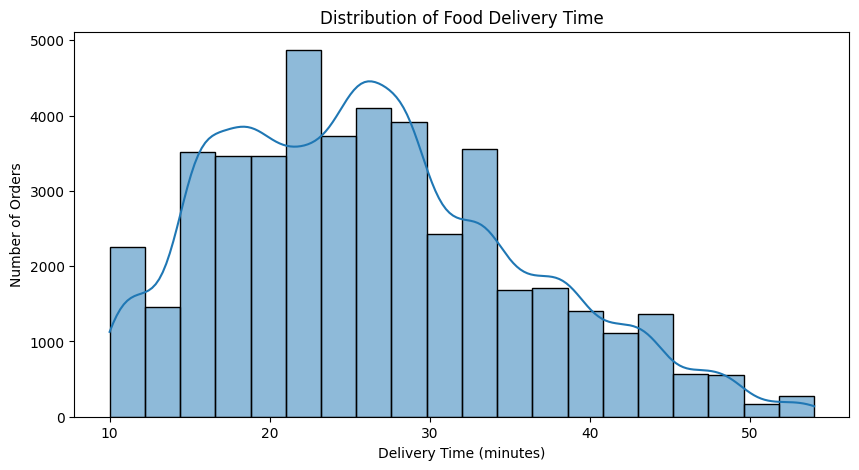

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    df["Time_taken(min)"],
    bins=20,
    kde=True
)

plt.title("Distribution of Food Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of Orders")

plt.show()

## 2. Late Delivery Analysis

A delivery taking more than 30 minutes is treated as a late delivery for this analysis.

### Business Question

> How significant is the late-delivery problem, and what proportion of orders are delivered within 30 minutes versus after 30 minutes?

In [7]:
df["Late_Delivery"] = np.where(
    df["Time_taken(min)"] > 30,
    "Late",
    "On Time"
)

In [8]:
df["Late_Delivery"].value_counts()

Late_Delivery
On Time    31987
Late       13606
Name: count, dtype: int64

In [9]:
late_delivery_summary = (
    df["Late_Delivery"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

late_delivery_summary

Late_Delivery
On Time    70.16
Late       29.84
Name: proportion, dtype: float64

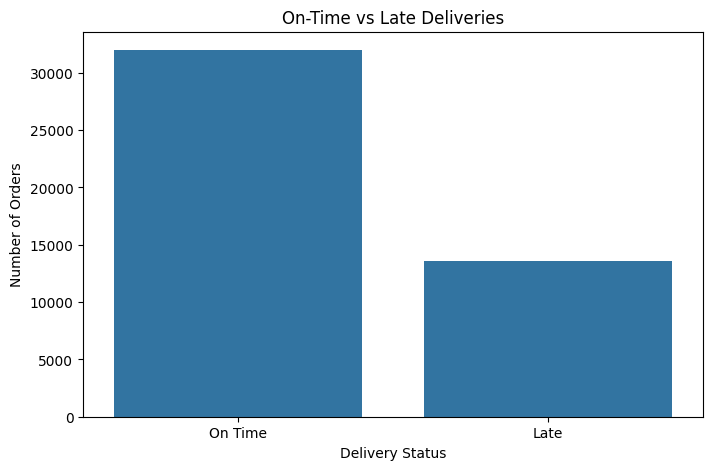

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Late_Delivery"
)

plt.title("On-Time vs Late Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")

plt.show()

### Interpretation

The analysis shows the proportion of deliveries that exceed the 30-minute threshold. This provides a baseline for identifying operational factors associated with delivery delays.

Further analysis will compare late deliveries across traffic, weather, distance, vehicles, delivery partners, and cities.

## 3. Traffic Impact on Delivery Time

Road traffic is a major operational factor that may influence how quickly delivery partners can complete orders.

### Business Questions

- What is the average delivery time under different traffic conditions?
- Which traffic condition has the highest average delivery time?
- Does heavy traffic have a higher late-delivery rate?

In [11]:
traffic_delivery_time = (
    df.groupby("Road_traffic_density")["Time_taken(min)"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean", ascending=False)
)

traffic_delivery_time

,count,mean,median
Road_traffic_density,,,
Jam,14143,31.18,31.0
High,4425,27.24,27.0
Medium,10947,26.70,27.0
NaN,601,26.54,26.0
Low,15477,21.27,20.0


In [12]:
traffic_late_rate = (
    df.groupby("Road_traffic_density")["Late_Delivery"]
    .apply(lambda x: (x == "Late").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

traffic_late_rate

Road_traffic_density
Jam        50.64
High       33.56
Medium     32.47
NaN        30.95
Low         7.87
Name: Late_Delivery, dtype: float64

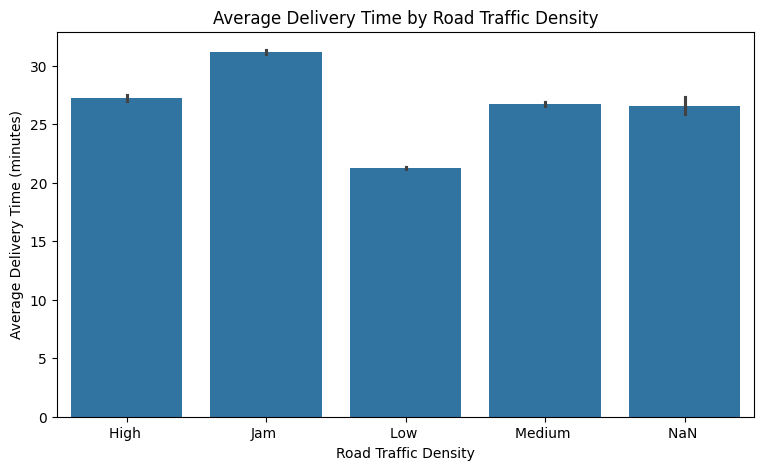

In [28]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Road_traffic_density",
    y="Time_taken(min)",
    estimator="mean"
)

plt.title("Average Delivery Time by Road Traffic Density")
plt.xlabel("Road Traffic Density")
plt.ylabel("Average Delivery Time (minutes)")
plt.xticks(rotation=0)

plt.show()

## 3. Traffic Impact on Delivery Time

### Interpretation

The analysis shows a clear relationship between **road traffic density and delivery performance**. Delivery time generally increases as traffic becomes heavier.

Orders delivered during **Jam traffic** had the highest average delivery time of **31.18 minutes**, while orders during **Low traffic** had the lowest average delivery time of **21.27 minutes**. This is a difference of approximately **9.91 minutes**.

The late-delivery analysis shows an even stronger pattern. **50.64% of deliveries during Jam traffic were late**, compared with only **7.87% during Low traffic**. High and Medium traffic had late-delivery rates of **33.56%** and **32.47%**, respectively.


## 4. Weather Impact on Delivery Time

Weather conditions may affect delivery speed and the likelihood of delays.

### Key Business Questions

* How does average delivery time vary across different weather conditions?
* Which weather condition has the highest average delivery time?
* Does bad weather lead to a higher late-delivery rate?
* Which weather condition has the highest late-delivery rate?


In [17]:
weather_delivery_time = (
    df.groupby("Weatherconditions")["Time_taken(min)"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean", ascending=False)
)

weather_delivery_time

,count,mean,median
Weatherconditions,,,
conditions Cloudy,7536,28.92,28.0
conditions Fog,7654,28.92,28.0
conditions Windy,7422,26.12,26.0
conditions Sandstorms,7495,25.88,26.0
conditions Stormy,7586,25.87,26.0
conditions Sunny,7284,21.86,20.0


In [19]:
weather_late_rate = (
    df.groupby("Weatherconditions")["Late_Delivery"]
    .apply(lambda x: (x == "Late").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

weather_late_rate

Weatherconditions
conditions Fog           43.79
conditions Cloudy        43.78
conditions Windy         26.56
conditions Sandstorms    25.95
conditions Stormy        25.53
conditions Sunny         12.52
Name: Late_Delivery, dtype: float64

<Axes: title={'center': 'Late Delivery Rate by Weather Condition'}, xlabel='Weather Condition', ylabel='Late Delivery Rate (%)'>

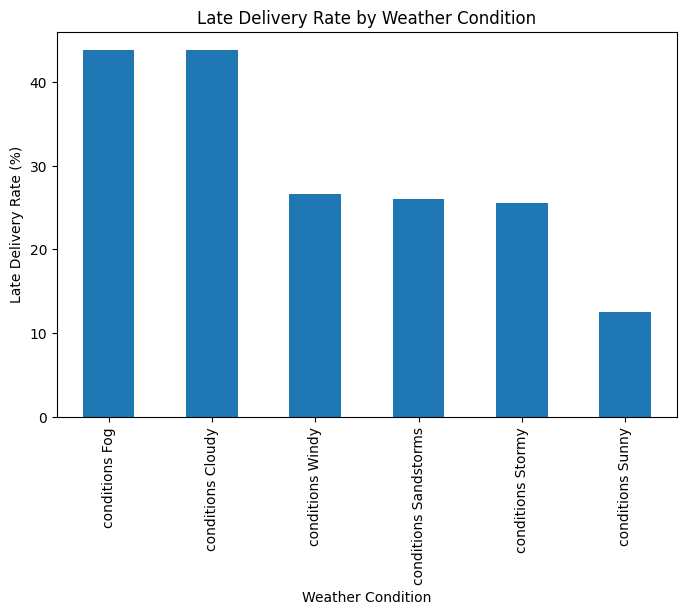

In [20]:
weather_late_rate.plot(
    kind="bar",
    figsize=(8, 5),
    title="Late Delivery Rate by Weather Condition",
    xlabel="Weather Condition",
    ylabel="Late Delivery Rate (%)"
)

### Interpretation

Weather conditions have a noticeable impact on delivery performance. **Cloudy and Foggy conditions** had the highest average delivery time at **28.92 minutes**, while **Sunny conditions** had the lowest at **21.86 minutes**.

The late-delivery analysis shows a similar pattern. **Foggy conditions had the highest late-delivery rate at 43.79%**, closely followed by **Cloudy conditions at 43.78%**. In comparison, Sunny conditions had the lowest late-delivery rate at **12.52%**.

### Business Insight

**Unfavorable weather conditions, particularly Foggy and Cloudy conditions, are associated with longer delivery times and a higher likelihood of late deliveries.** The company could consider adjusting delivery time estimates and planning additional operational support during such weather conditions.

### Conclusion

Weather appears to be an important factor affecting delivery performance. Deliveries during Foggy and Cloudy conditions are substantially more likely to be delayed compared with deliveries during Sunny conditions.


## 5. Weather × Traffic Impact

Weather and traffic together may have a stronger impact on delivery performance than either factor alone.

### Key Business Questions

* Which weather and traffic combination has the highest average delivery time?
* Do poor weather and heavy traffic together increase delivery delays?
* Which weather–traffic combination has the highest late-delivery rate?


In [25]:
weather_traffic_delivery = (
    df.groupby(["Weatherconditions", "Road_traffic_density"])["Time_taken(min)"]
    .agg(["count","mean","median"])
    .round(2)
    .sort_values("mean",ascending=False)
)

weather_traffic_delivery

count   mean  median
Weatherconditions     Road_traffic_density                      
conditions Fog        Jam                    2429  36.81    37.0
conditions Cloudy     Jam                    2349  36.69    37.0
conditions Windy      Jam                    2351  30.22    29.0
conditions Sandstorms Jam                    2399  30.02    29.0
conditions Stormy     Jam                    2323  29.85    29.0
conditions Cloudy     High                    744  28.94    29.0
                      Medium                 1838  28.48    30.0
conditions Fog        High                    776  28.43    28.0
                      Medium                 1852  28.04    29.0
conditions Windy      Medium                 1852  27.89    27.0
conditions Stormy     High                    733  27.85    28.0
conditions Sandstorms Medium                 1786  27.74    27.0
                      High                    701  27.71    28.0
conditions Stormy     Medium                 1831  27.68    27.0
conditions Windy      High                    735  26.97    27.0
conditions Sunny      High                    735  23.45    20.0
                      Jam                    2289  23.08    21.0
conditions Fog        Low                    2597  22.30    20.0
conditions Cloudy     Low                    2605  22.21    20.0
conditions Sunny      Low                    2475  21.45    20.0
conditions Stormy     Low                    2699  20.68    21.0
conditions Windy      Low                    2484  20.67    21.0
conditions Sandstorms Low                    2609  20.30    20.0
conditions Sunny      Medium                 1785  20.20    19.0

In [26]:
weather_traffic_late_rate = (
    df.groupby(["Weatherconditions", "Road_traffic_density"])["Late_Delivery"]
    .apply(lambda x: (x == "Late").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

weather_traffic_late_rate

Weatherconditions      Road_traffic_density
conditions Fog         Jam                     76.08
conditions Cloudy      Jam                     74.84
                       Medium                  48.31
conditions Fog         Medium                  45.90
conditions Windy       Jam                     45.56
conditions Sandstorms  Jam                     44.52
conditions Stormy      Jam                     43.35
                       High                    38.74
conditions Sandstorms  High                    38.37
conditions Cloudy      High                    37.63
conditions Fog         High                    35.31
conditions Windy       High                    34.15
conditions Stormy      Medium                  31.13
conditions Sandstorms  Medium                  31.08
conditions Windy       Medium                  31.05
conditions Sunny       Jam                     17.82
                       High                    17.14
conditions Fog         Low                     14.63
co

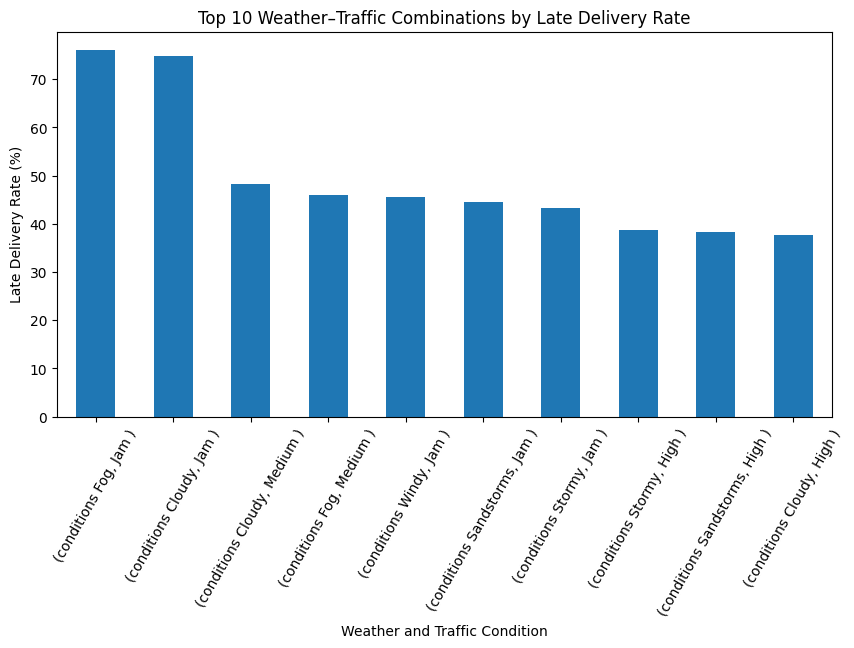

In [31]:
top_weather_traffic = weather_traffic_late_rate.head(10)

top_weather_traffic.plot(
    kind="bar",
    figsize=(10, 5),
    title="Top 10 Weather–Traffic Combinations by Late Delivery Rate",
    xlabel="Weather and Traffic Condition",
    ylabel="Late Delivery Rate (%)"
)
plt.xticks(rotation=60)
plt.show()

## 6. Distance Impact on Delivery Time

Delivery distance may directly affect delivery time and the likelihood of delays.

### Key Business Questions

- How does delivery distance affect delivery time?
- Does longer distance lead to a higher late-delivery rate?
- Which distance range has the highest late-delivery rate?

In [32]:
import numpy as np

lat_diff = np.radians(
    df["Delivery_location_latitude"] - df["Restaurant_latitude"]
)

lon_diff = np.radians(
    df["Delivery_location_longitude"] - df["Restaurant_longitude"]
)

a = (
    np.sin(lat_diff / 2) ** 2
    + np.cos(np.radians(df["Restaurant_latitude"]))
    * np.cos(np.radians(df["Delivery_location_latitude"]))
    * np.sin(lon_diff / 2) ** 2
)

df["Distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

In [33]:
df["Distance_km"].describe().round(2)

count    41953.00
mean       107.06
std       1146.12
min          1.47
25%          4.66
50%          9.22
75%         13.76
max      19692.67
Name: Distance_km, dtype: float64

In [34]:
df[df["Distance_km"] > 50]["Distance_km"].describe().round(2)

count      431.00
mean      9484.67
std       6252.62
min       2216.07
25%       4434.86
50%       5897.02
75%      17132.39
max      19692.67
Name: Distance_km, dtype: float64

In [35]:
zero_coordinate_rows = (
    (df["Restaurant_latitude"] == 0) |
    (df["Restaurant_longitude"] == 0) |
    (df["Delivery_location_latitude"] == 0) |
    (df["Delivery_location_longitude"] == 0)
)

zero_coordinate_rows.sum()

np.int64(0)

In [36]:
df.loc[zero_coordinate_rows, "Distance_km"].describe().round(2)

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Distance_km, dtype: float64

In [37]:
df["Distance_km"].quantile([0.90, 0.95, 0.99, 0.995, 0.999]).round(2)

0.900       19.40
0.950       20.18
0.990     2231.61
0.995     5902.18
0.999    17666.31
Name: Distance_km, dtype: float64

In [38]:
(df["Distance_km"] > 20).sum()

np.int64(2210)

In [40]:
df_distance = df[df["Distance_km"] <= 20].copy()
df_distance["Distance_km"].describe().round(2)

count    39743.00
mean         9.24
std          5.24
min          1.47
25%          4.62
50%          9.09
75%         12.48
max         19.98
Name: Distance_km, dtype: float64

In [41]:
df_distance["Distance_Group"] = pd.cut(
    df_distance["Distance_km"],
    bins=[0, 5, 10, 15, 20],
    labels=["0–5 km", "5–10 km", "10–15 km", "15–20 km"]
)

distance_delivery_time = (
    df_distance.groupby("Distance_Group", observed=False)["Time_taken(min)"]
    .agg(["count", "mean", "median"])
    .round(2)
)

distance_delivery_time

,count,mean,median
Distance_Group,,,
0–5 km,11187,22.18,21.0
5–10 km,11187,24.39,25.0
10–15 km,11183,29.84,29.0
15–20 km,6186,29.90,29.0


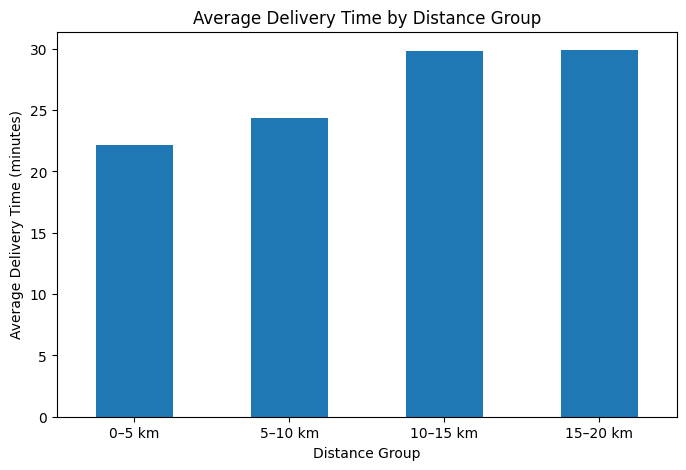

In [42]:
distance_delivery_time["mean"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Delivery Time by Distance Group",
    xlabel="Distance Group",
    ylabel="Average Delivery Time (minutes)"
)

plt.xticks(rotation=0)
plt.show()

In [44]:
distance_late_rate = (
    df_distance.groupby("Distance_Group", observed=False)["Late_Delivery"]
    .apply(lambda x: (x == "Late").mean() * 100)
    .round(2)
)

distance_late_rate

Distance_Group
0–5 km      12.39
5–10 km     21.16
10–15 km    45.55
15–20 km    45.34
Name: Late_Delivery, dtype: float64

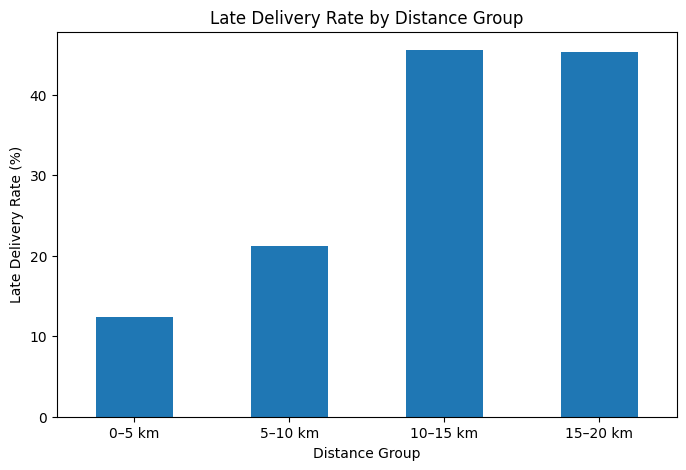

In [45]:
distance_late_rate.plot(
    kind="bar",
    figsize=(8, 5),
    title="Late Delivery Rate by Distance Group",
    xlabel="Distance Group",
    ylabel="Late Delivery Rate (%)"
)

plt.xticks(rotation=0)
plt.show()

### Interpretation

Delivery distance has a clear impact on delivery performance. Average delivery time increased from 22.18 minutes for deliveries within 0–5 km to 29.90 minutes for deliveries between 15–20 km.

The late-delivery rate also increased significantly with distance. Only 12.39% of deliveries within 0–5 km were late, compared with 45.55% for the 10–15 km range and 45.34% for the 15–20 km range.

### Business Insight

Longer delivery distances are strongly associated with longer delivery times and a higher probability of late delivery. Deliveries above 10 km have a late-delivery rate of around 45%, compared with only 12.39% for deliveries below 5 km.

The company could use distance-based delivery time estimates, assign nearby delivery partners where possible, and apply additional planning for longer-distance orders.

### Conclusion

Delivery distance is an important factor affecting delivery performance. As distance increases, delivery time generally increases and the likelihood of late delivery rises substantially. Orders above 10 km represent a higher-risk segment for delivery delays.

## 7. Vehicle Type Impact on Delivery Time

Vehicle characteristics may influence delivery speed and overall delivery performance.

### Key Business Questions

- How does delivery time vary across different vehicle types?
- Which vehicle type has the highest average delivery time?
- Does vehicle type affect the late-delivery rate?

In [46]:
vehicle_delivery_time = (
    df.groupby("Type_of_vehicle")["Time_taken(min)"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean", ascending=False)
)

vehicle_delivery_time

,count,mean,median
Type_of_vehicle,,,
motorcycle,26435,27.61,26.0
bicycle,68,26.43,26.0
scooter,15276,24.48,24.0
electric_scooter,3814,24.47,24.0


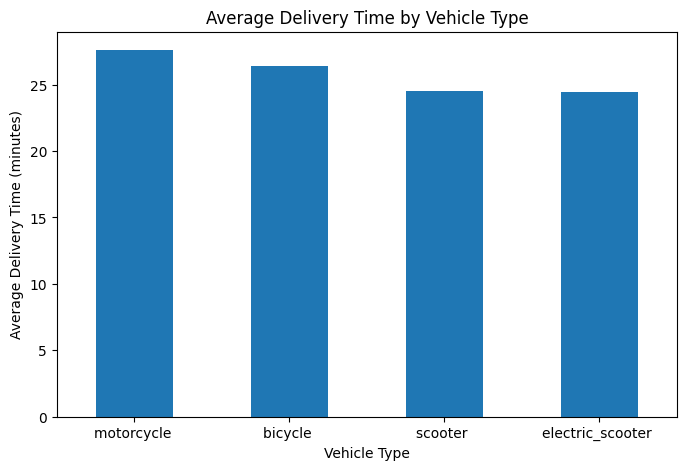

In [47]:
vehicle_delivery_time["mean"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Delivery Time by Vehicle Type",
    xlabel="Vehicle Type",
    ylabel="Average Delivery Time (minutes)"
)

plt.xticks(rotation=0)
plt.show()

In [50]:
vehicle_late_rate = (
    df.groupby("Type_of_vehicle")["Late_Delivery"]
    .apply(lambda x: (x == "Late").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)
vehicle_late_rate

Type_of_vehicle
motorcycle           33.94
bicycle              30.88
scooter              24.34
electric_scooter     23.44
Name: Late_Delivery, dtype: float64

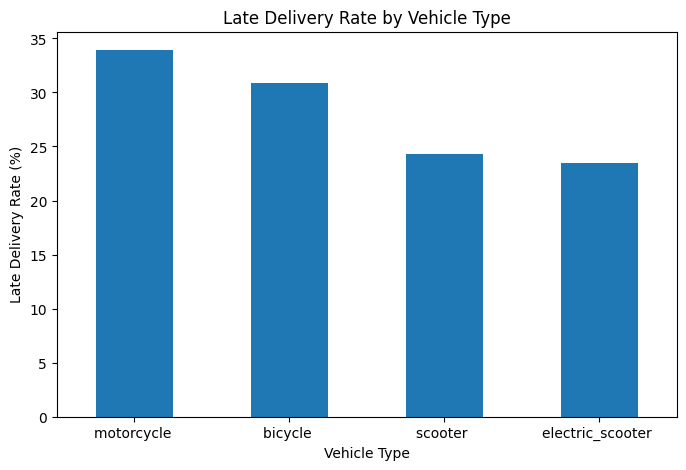

In [51]:
vehicle_late_rate.plot(
    kind="bar",
    figsize=(8, 5),
    title="Late Delivery Rate by Vehicle Type",
    xlabel="Vehicle Type",
    ylabel="Late Delivery Rate (%)"
)

plt.xticks(rotation=0)
plt.show()

### Interpretation

Vehicle type has a noticeable relationship with delivery performance. Motorcycles had the highest average delivery time at 27.61 minutes, while electric scooters had the lowest at 24.47 minutes.

The late-delivery analysis shows a similar pattern. Motorcycles had the highest late-delivery rate at 33.94%, compared with 23.44% for electric scooters.

### Business Insight

Motorcycle deliveries show relatively slower performance and a higher likelihood of late delivery compared with scooters and electric scooters. The company could evaluate vehicle allocation and consider using faster or more efficient vehicles for suitable delivery routes.

### Conclusion

Vehicle type appears to influence delivery performance. Motorcycles have the highest average delivery time and late-delivery rate, while electric scooters show the lowest values among the available vehicle types.

## 8. Delivery Partner Performance

Delivery partner characteristics may influence delivery speed and overall delivery performance.

### Key Business Questions

- How does delivery time vary across delivery partners?
- Which delivery partners have the fastest and slowest average delivery times?
- Does delivery partner rating relate to delivery performance?
- Do higher-rated delivery partners have lower late-delivery rates?

In [53]:
df["Delivery_person_ID"].nunique()

1320

In [54]:
top_delivery_partners = (
    df["Delivery_person_ID"]
    .value_counts()
    .head(10)
)

top_delivery_partners

Delivery_person_ID
PUNERES01DEL01       67
JAPRES11DEL02        67
VADRES08DEL02        66
RANCHIRES02DEL01     66
HYDRES04DEL02        66
VADRES11DEL02        66
JAPRES03DEL01        66
SURRES11DEL01        65
JAPRES09DEL02        65
INDORES15DEL01       65
Name: count, dtype: int64

In [55]:
top_partner_ids = top_delivery_partners.index

top_partner_delivery_time = (
    df[df["Delivery_person_ID"].isin(top_partner_ids)]
    .groupby("Delivery_person_ID")["Time_taken(min)"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean")
)

top_partner_delivery_time

,count,mean,median
Delivery_person_ID,,,
VADRES08DEL02,66,25.08,23.5
SURRES11DEL01,65,25.60,24.0
JAPRES09DEL02,65,26.74,25.0
RANCHIRES02DEL01,66,26.92,26.5
JAPRES03DEL01,66,27.03,27.0
HYDRES04DEL02,66,27.15,26.0
INDORES15DEL01,65,27.37,27.0
PUNERES01DEL01,67,27.93,27.0
JAPRES11DEL02,67,28.60,29.0


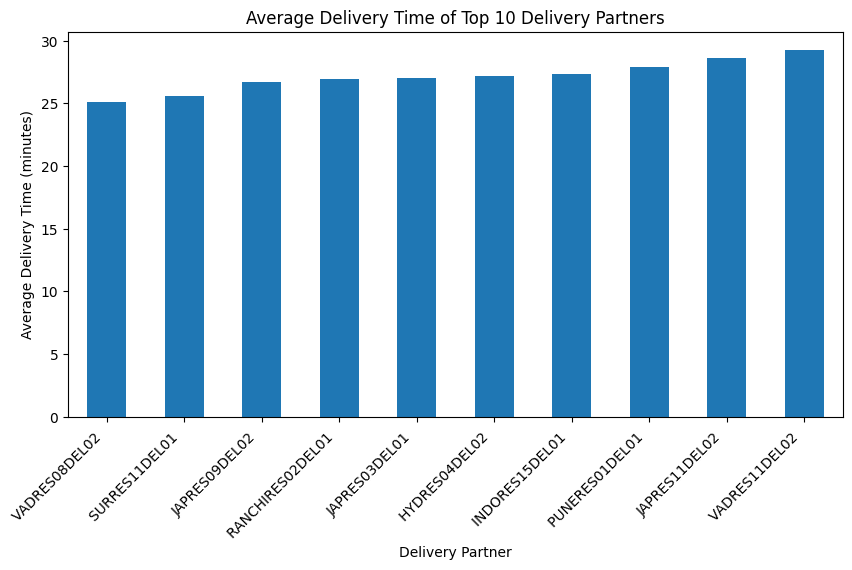

In [59]:
top_partner_delivery_time["mean"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Delivery Time of Top 10 Delivery Partners",
    xlabel="Delivery Partner",
    ylabel="Average Delivery Time (minutes)"
)

plt.xticks(rotation=45, ha="right")
plt.show()

In [60]:
rating_delivery_time = (
    df.groupby("Delivery_person_Ratings")["Time_taken(min)"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_index()
)

rating_delivery_time

,count,mean,median
Delivery_person_Ratings,,,
1.0,38,26.00,26.5
2.5,20,37.30,35.5
2.6,22,38.59,39.0
2.7,22,35.86,36.5
2.8,19,36.63,37.0
2.9,19,38.53,39.0
3.0,6,32.67,32.5
3.1,29,36.55,35.0
3.2,29,36.34,36.0


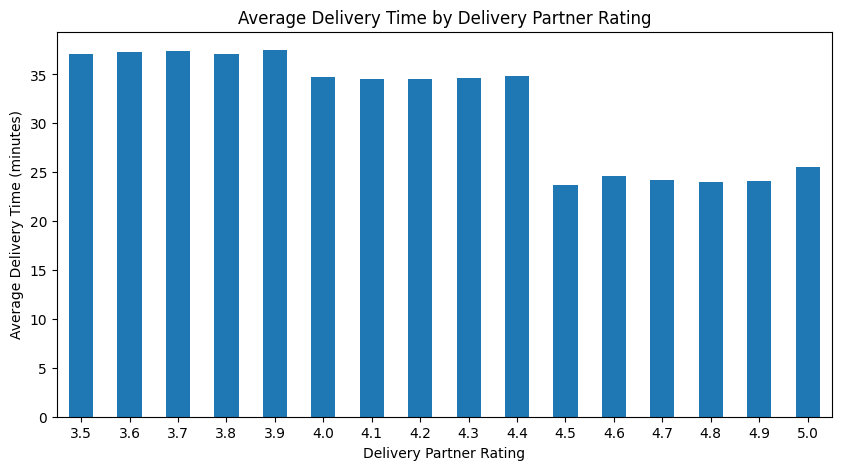

In [61]:
rating_delivery_time_filtered = rating_delivery_time[
    rating_delivery_time["count"] >= 100
]

rating_delivery_time_filtered["mean"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Delivery Time by Delivery Partner Rating",
    xlabel="Delivery Partner Rating",
    ylabel="Average Delivery Time (minutes)"
)

plt.xticks(rotation=0)
plt.show()

In [62]:
rating_late_rate = (
    df.groupby("Delivery_person_Ratings")["Late_Delivery"]
    .apply(lambda x: (x == "Late").mean() * 100)
    .round(2)
)

rating_late_rate

Delivery_person_Ratings
1.0     18.42
2.5    100.00
2.6    100.00
2.7    100.00
2.8    100.00
2.9    100.00
3.0    100.00
3.1    100.00
3.2    100.00
3.3    100.00
3.4    100.00
3.5    100.00
3.6    100.00
3.7    100.00
3.8    100.00
3.9    100.00
4.0     84.77
4.1     81.05
4.2     80.82
4.3     81.19
4.4     80.53
4.5     12.08
4.6     18.03
4.7     16.80
4.8     16.02
4.9     17.03
5.0     25.65
Name: Late_Delivery, dtype: float64

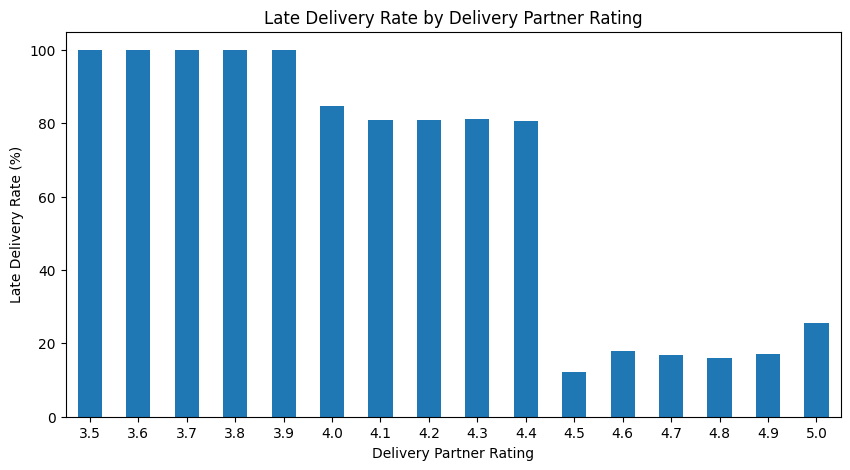

In [63]:
rating_late_rate_filtered = rating_late_rate[
    df["Delivery_person_Ratings"].value_counts() >= 100
]

rating_late_rate_filtered.plot(
    kind="bar",
    figsize=(10, 5),
    title="Late Delivery Rate by Delivery Partner Rating",
    xlabel="Delivery Partner Rating",
    ylabel="Late Delivery Rate (%)"
)

plt.xticks(rotation=0)
plt.show()

### Interpretation

Delivery partner performance varies across both individual partners and their ratings. Among the top 10 delivery partners by order volume, average delivery time ranged from 25.08 minutes to 29.24 minutes.

Delivery partner ratings also show a strong relationship with delivery performance. Partners with ratings of 4.5–4.9 had substantially lower average delivery times and late-delivery rates compared with partners rated below 4.5.

### Business Insight

Higher-rated delivery partners generally demonstrate better delivery performance, with lower delivery times and substantially lower late-delivery rates. The company could use delivery performance and rating data to identify high-performing partners, provide targeted training to lower-performing partners, and improve delivery allocation.

### Conclusion

Delivery partner performance is an important factor in delivery efficiency. Higher-rated partners generally achieve faster deliveries and fewer delays, indicating that partner performance monitoring can help improve overall service quality.

## 9. Multiple Deliveries Impact on Delivery Time

Handling multiple deliveries in a single trip may affect delivery speed and the likelihood of delays.

### Key Business Questions

- How does the number of multiple deliveries affect delivery time?
- Does handling multiple deliveries increase the late-delivery rate?
- Which multiple-delivery category has the highest late-delivery rate?

In [64]:
df["multiple_deliveries"].value_counts(dropna=False)

multiple_deliveries
1       28159
0       14095
2        1985
NaN       993
3         361
Name: count, dtype: int64

In [65]:
multiple_delivery_time = (
    df.groupby("multiple_deliveries")["Time_taken(min)"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean", ascending=False)
)

multiple_delivery_time

,count,mean,median
multiple_deliveries,,,
3,361,47.82,48.0
2,1985,40.45,40.0
1,28159,26.86,26.0
0,14095,22.88,22.0
NaN,993,22.77,21.0


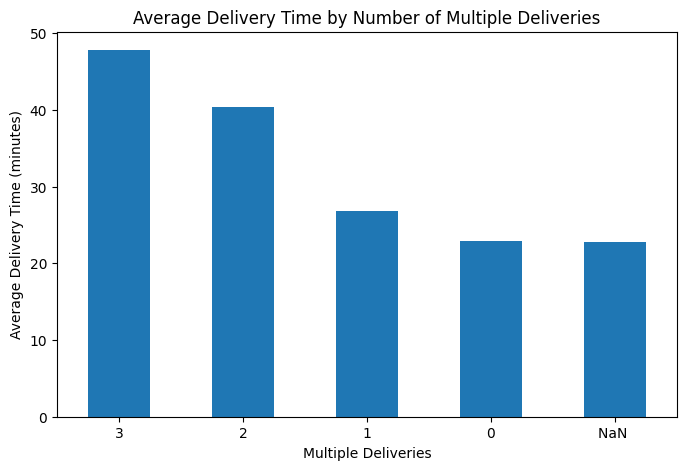

In [66]:
multiple_delivery_time["mean"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Delivery Time by Number of Multiple Deliveries",
    xlabel="Multiple Deliveries",
    ylabel="Average Delivery Time (minutes)"
)

plt.xticks(rotation=0)
plt.show()

In [67]:
multiple_delivery_late_rate = (
    df.groupby("multiple_deliveries")["Late_Delivery"]
    .apply(lambda x: (x == "Late").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

multiple_delivery_late_rate

multiple_deliveries
2       100.00
3       100.00
1        30.26
NaN      18.63
0        18.12
Name: Late_Delivery, dtype: float64

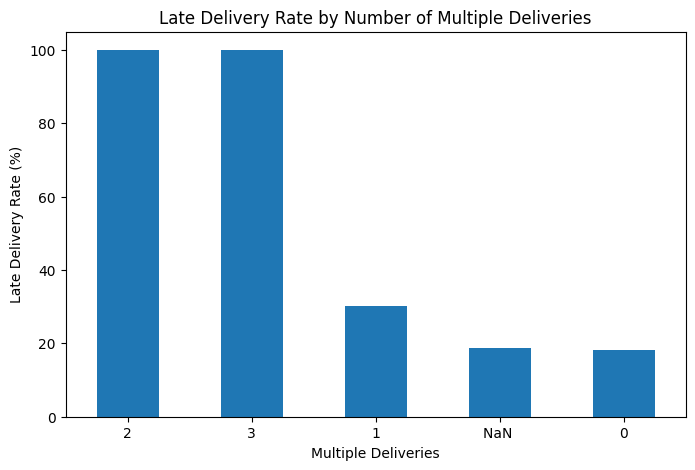

In [68]:
multiple_delivery_late_rate.plot(
    kind="bar",
    figsize=(8, 5),
    title="Late Delivery Rate by Number of Multiple Deliveries",
    xlabel="Multiple Deliveries",
    ylabel="Late Delivery Rate (%)"
)

plt.xticks(rotation=0)
plt.show()

### Interpretation

Multiple deliveries have a strong impact on delivery performance. Average delivery time increased from 22.88 minutes for orders with no multiple deliveries to 40.45 minutes for orders with 2 multiple deliveries and 47.82 minutes for orders with 3 multiple deliveries.

The late-delivery rate also increased significantly. Orders with no multiple deliveries had an 18.12% late-delivery rate, compared with 30.26% for 1 multiple delivery. Both 2 and 3 multiple deliveries had a late-delivery rate of 100% in this dataset.

### Business Insight

Handling multiple deliveries in a single trip substantially increases delivery time and the likelihood of delays. The company could optimize delivery batching, limit the number of orders assigned to a delivery partner at once, and consider traffic and distance before combining multiple deliveries.

### Conclusion

Multiple deliveries are a major factor affecting delivery performance. As the number of deliveries handled together increases, both delivery time and the probability of late delivery increase substantially.`m

## 10. City Analysis

City-level differences may reveal locations with better or worse delivery performance.

### Key Business Questions

- How does average delivery time vary across cities?
- Which city has the highest late-delivery rate?
- Which city has the best delivery performance?

In [70]:
city_delivery_time = (
    df.groupby("City")["Time_taken(min)"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean", ascending=False)
)

city_delivery_time

,count,mean,median
City,,,
Semi-Urban,164,49.73,49.0
Metropolitian,34093,27.32,27.0
Urban,10136,22.98,22.0
NaN,1200,22.06,21.0


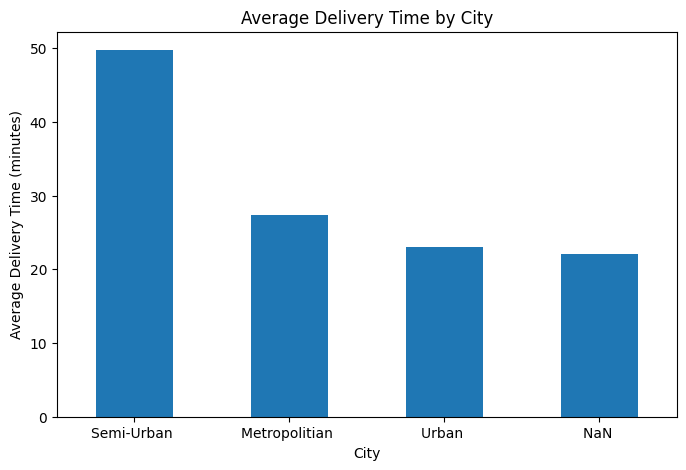

In [71]:
city_delivery_time.drop(index="NaN", errors="ignore")["mean"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Average Delivery Time by City",
    xlabel="City",
    ylabel="Average Delivery Time (minutes)"
)

plt.xticks(rotation=0)
plt.show()

In [72]:
city_late_rate = (
    df.groupby("City")["Late_Delivery"]
    .apply(lambda x: (x == "Late").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

city_late_rate

City
Semi-Urban        100.00
Metropolitian      33.34
Urban              18.66
NaN                15.42
Name: Late_Delivery, dtype: float64

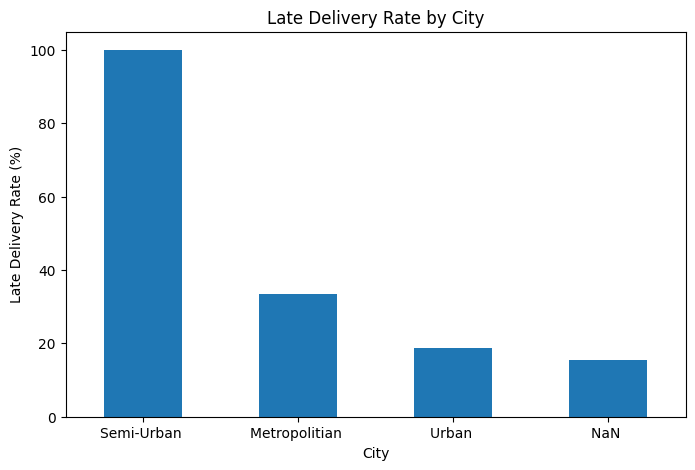

In [73]:
city_late_rate.drop(index="NaN", errors="ignore").plot(
    kind="bar",
    figsize=(8, 5),
    title="Late Delivery Rate by City",
    xlabel="City",
    ylabel="Late Delivery Rate (%)"
)

plt.xticks(rotation=0)
plt.show()

### Interpretation

City-level analysis shows substantial differences in delivery performance. Urban areas had the lowest average delivery time at 22.98 minutes and the lowest late-delivery rate among the identified city categories at 18.66%.

Metropolitian areas had an average delivery time of 27.32 minutes and a late-delivery rate of 33.34%. Semi-Urban areas had the highest average delivery time at 49.73 minutes and a 100% late-delivery rate.

However, Semi-Urban results should be interpreted cautiously because the category contains only 164 deliveries compared with 34,093 Metropolitian and 10,136 Urban deliveries.

### Business Insight

Delivery performance varies significantly by city type. Urban areas demonstrate stronger delivery performance, while Metropolitian areas experience higher delivery times and late-delivery rates. Semi-Urban deliveries may require additional operational attention, although the smaller sample size limits the reliability of this comparison.

### Conclusion

City type appears to be an important factor affecting delivery performance. Urban areas show the best overall performance, while Semi-Urban areas show the highest delays and late-delivery rates in this dataset.

## 11. Outlier Analysis

Outlier analysis helps identify unusual delivery times and other extreme values that may affect business conclusions.

## Key Business Questions
- Are there unusually high or low delivery times?
- How much do outliers affect overall delivery performance?
- Should extreme delivery times be investigated separately?

In [75]:
Q1 = df["Time_taken(min)"].quantile(0.25)
Q3 = df["Time_taken(min)"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 19.0
Q3: 32.0
IQR: 13.0
Lower Bound: -0.5
Upper Bound: 51.5


In [76]:
outliers = df[
    (df["Time_taken(min)"] < lower_bound) |
    (df["Time_taken(min)"] > upper_bound)
]

print("Number of outliers:", len(outliers))
print("Percentage of outliers:", round(len(outliers) / len(df) * 100, 2), "%")

Number of outliers: 270
Percentage of outliers: 0.59 %


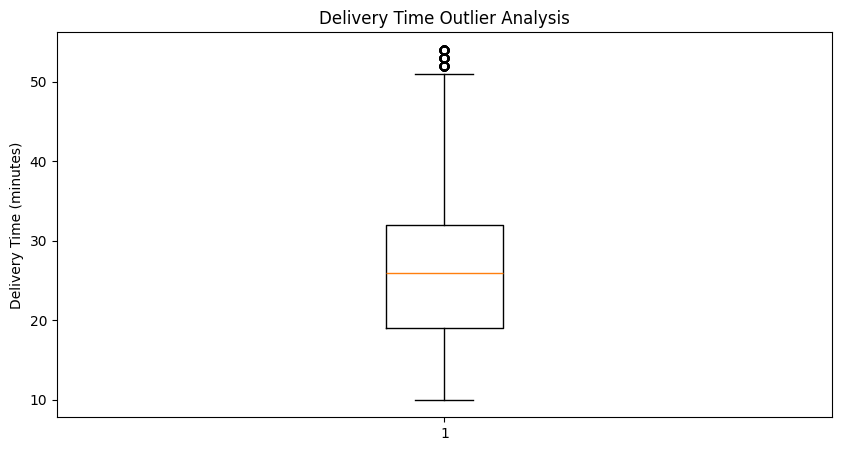

In [77]:
plt.figure(figsize=(10, 5))

plt.boxplot(df["Time_taken(min)"].dropna())

plt.title("Delivery Time Outlier Analysis")
plt.ylabel("Delivery Time (minutes)")

plt.show()

### Business Insight

Only 0.59% of deliveries are statistical outliers, indicating that extreme delivery times are relatively rare.
These records should not be removed automatically because they may represent genuine operational issues.
Instead, they can be investigated separately to identify the causes of unusually long deliveries.

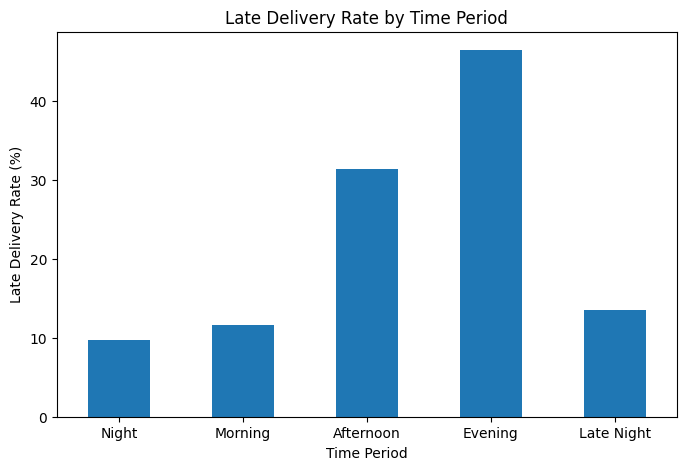

In [91]:
time_period_late_rate.plot(
    kind="bar",
    figsize=(8, 5),
    title="Late Delivery Rate by Time Period",
    xlabel="Time Period",
    ylabel="Late Delivery Rate (%)"
)

plt.xticks(rotation=0)
plt.show()

### Business Insight

Time of day has a strong impact on delivery performance. Evening deliveries have the highest average delivery time at 30.11 minutes and the highest late-delivery rate at 46.39%.

Morning deliveries perform best, with an average delivery time of 21.85 minutes and a late-delivery rate of 11.58%.

The business should prepare additional delivery capacity and optimize rider allocation during evening hours to reduce delays.

## 12. Correlation Analysis

Correlation analysis helps identify numerical variables that are associated with delivery time.

### Key Business Questions

- Which numerical variables are most strongly related to delivery time?
- Is delivery distance associated with longer delivery times?
- Are delivery partner ratings or vehicle condition related to delivery performance?

In [93]:
df["multiple_deliveries"] = pd.to_numeric(
    df["multiple_deliveries"],
    errors="coerce"
)

correlation_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Vehicle_condition",
    "multiple_deliveries",
    "Distance_km",
    "Time_taken(min)"
]

correlation_df = df[correlation_columns]

correlation_matrix = correlation_df.corr()

correlation_matrix["Time_taken(min)"].sort_values(ascending=False)

Time_taken(min)            1.000000
multiple_deliveries        0.387051
Delivery_person_Age        0.300293
Distance_km               -0.002911
Vehicle_condition         -0.234398
Delivery_person_Ratings   -0.341199
Name: Time_taken(min), dtype: float64

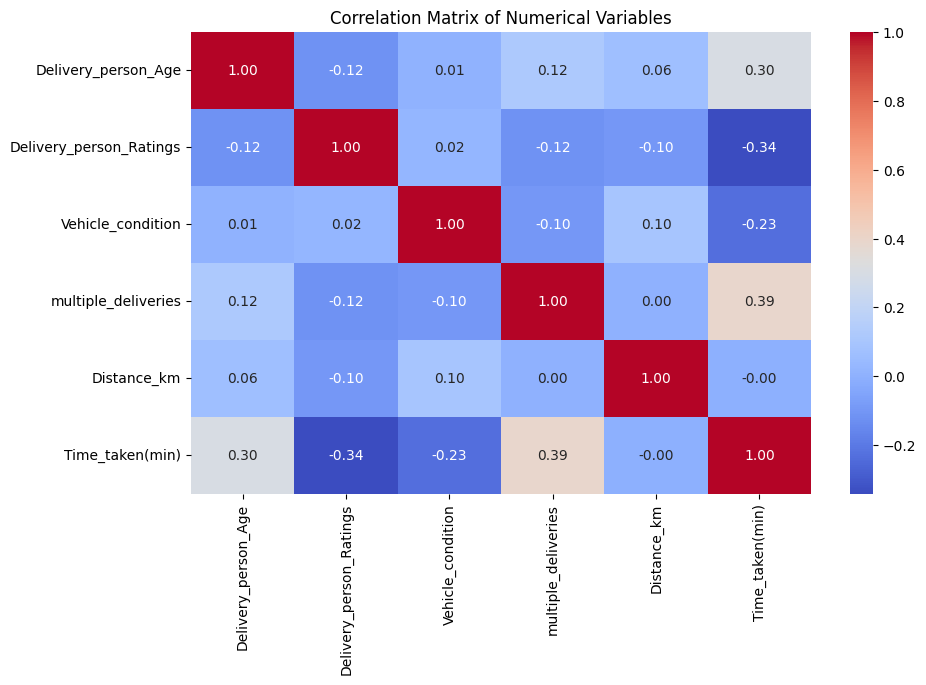

In [94]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Variables")
plt.show()

### Business Insight

Multiple deliveries have the strongest positive relationship with delivery time, indicating that handling several orders in one trip can increase delivery duration. Delivery partner ratings show a moderate negative relationship, suggesting that higher-rated partners generally complete deliveries faster.

Vehicle condition also has a weak negative relationship with delivery time, while delivery partner age has a weak positive relationship.

Distance shows almost no linear correlation in the full dataset. This is mainly influenced by extreme distance values identified during outlier analysis. The earlier distance-group analysis provides a clearer business view and showed that deliveries above 10 km had substantially higher late-delivery rates.

Overall, operational factors such as multiple deliveries, delivery partner performance, and vehicle condition appear more useful for understanding delivery time than simple linear correlation alone.

## Key Findings

- **Traffic is a major driver of delays:** deliveries during Jam traffic averaged **31.18 minutes**, compared with **21.27 minutes** during Low traffic.
- **Weather affects delivery performance:** Fog and Cloudy conditions had the highest average delivery times at approximately **28.92 minutes** and late-delivery rates of about **44%**.
- **Weather and traffic together create the highest risk:** Fog + Jam had an average delivery time of **36.81 minutes** and a late-delivery rate of **76.08%**.
- **Distance increases delivery risk:** deliveries between **10–20 km** had late-delivery rates of approximately **45%**, compared with **12.39%** for deliveries under 5 km.
- **Vehicle type matters:** motorcycles had the highest average delivery time (**27.61 minutes**) and late-delivery rate (**33.94%**), while electric scooters had lower delivery times and late-delivery rates.
- **Multiple deliveries significantly increase delivery time:** deliveries involving 2 or 3 orders had very high late-delivery rates, although these groups have smaller sample sizes.
- **Delivery partner performance varies:** the fastest and slowest high-volume partners showed a difference of more than **4 minutes** in average delivery time.
- **Overall late deliveries account for 29.84% of orders**, meaning nearly 3 out of every 10 deliveries take more than 30 minutes.